In [30]:
import pandas as pd
import numpy as np
from datetime import timedelta
from pyomo import environ
from pyomo.core import *
import pyomo.environ as pyo
np.random.seed(0)
from utils import *
import matplotlib.pyplot as plt

import sys
import os
sys.path.append(os.path.abspath('../../src'))

import warnings
warnings.filterwarnings("ignore")

## Data

In [31]:
data = pd.read_csv('data_house_japan/data_clean.csv', index_col=0)
data.index = pd.to_datetime(data.index)

y = data['demand']
X = data.drop(['demand'], axis=1, inplace=False)

In [32]:
val_ind = X.index[(X.index >= pd.to_datetime('2018-11-01')) & (X.index < pd.to_datetime('2018-12-01'))]
test_ind = X.index[X.index >= pd.to_datetime('2018-12-01')]

## Optimization Model

In [33]:
def vpp_opt(pred_da, pred_solar, ramp_ch, ramp_ds, eta_ch, eta_ds, bat_maxcap, bat_initq, balance_price, n_sc, contextual_sample):
    
    model = pyo.ConcreteModel()
    
    model.N = pyo.RangeSet(0,23)
    model.W = pyo.RangeSet(1,n_sc) # scenarios
    model.var_ind = pyo.Set(initialize=contextual_sample.columns.sort_values())
    
    pi = [1/n_sc for i in range(n_sc)]
    exp_da = pred_da.mean(axis=1)
    
    
    # Variables
    model.x = pyo.Var(model.var_ind, model.N, within=pyo.Reals) # first stage decisions about price and contextual variables
    model.q_da = pyo.Var(model.N, within=pyo.Reals) # quantity of energy to buy/sell in the day-ahead market
    model.q_bal = pyo.Var(model.N, model.W, within=pyo.NonNegativeReals) # quantity of energy to buy in the balance market
    
    model.B = pyo.Var(model.N, model.W, within=pyo.NonNegativeReals) # battery status at time t and scenario omega
    model.delta_ds = pyo.Var(model.N, model.W, within=pyo.NonNegativeReals) # quantity to charge and discharge into the batteries
    model.delta_ch = pyo.Var(model.N, model.W, within=pyo.NonNegativeReals)
    
    model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals) # learned variables (demand)
    
    model.profit = pyo.Var(model.W, within=pyo.Reals) # saving profit per scenario
    
    
    
    #definition of the objective function
    def obj_expression(model):
        return sum(pi[w-1] * model.profit[w] for w in model.W)
    model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)
    
    
    #saving profit  
    def const1_rule(model, w):
        return model.profit[w] ==  sum(model.y['demand', n, w]*model.x['price',n] - pred_da[n,w-1]*model.q_da[n] - balance_price*model.q_bal[n,w] for n in model.N)
    model.const1 = pyo.Constraint(model.W, rule=const1_rule)
    
    
    #constraint demand balance
    def const2_rule(model,n,w): 
        return model.y['demand', n, w] <=  model.q_da[n] + model.q_bal[n,w] + pred_solar[n,w-1] + eta_ds*model.delta_ds[n,w] - model.delta_ch[n,w]
    model.const2 = pyo.Constraint(model.N, model.W, rule=const2_rule)
    
    
    #constraint for charging ramp
    def const3_rule(model,n,w):
        return model.delta_ch[n,w] <= ramp_ch
    model.const3 = pyo.Constraint(model.N, model.W, rule=const3_rule)
    
    
    #constraint for discharging ramp
    def const4_rule(model,n,w):
        return model.delta_ds[n,w] <= ramp_ds
    model.const4 = pyo.Constraint(model.N, model.W, rule=const4_rule)
    
    
    #constraint for battery status
    def const5_rule(model,n,w):
        if n==23:
            return pyo.Constraint.Skip
        else:
            return model.B[n+1,w] == model.B[n,w] - model.delta_ds[n,w] + eta_ch * model.delta_ch[n,w]
    model.const5 = pyo.Constraint(model.N, model.W, rule=const5_rule)
    
    
    #constraint for battery max capacity
    def const6_rule(model,n,w):
        return model.B[n,w] <= bat_maxcap
    model.const6 = pyo.Constraint(model.N, model.W, rule=const6_rule)
    
    
    #constraint for battery init 
    def const7_rule(model,w):
        return model.B[0,w] == bat_initq
    model.const7 = pyo.Constraint(model.W, rule=const7_rule)
    
    def const8_rule(model):
        return sum(model.B[23,w] for w in model.W )/n_sc >= bat_initq
    model.const8 = pyo.Constraint(rule=const8_rule)
    
    
    #constraint for fixing contextual information
    def const9_rule(model,x_ind,n):
        if x_ind=='price':
            return pyo.Constraint.Skip
        else:
            return model.x[x_ind,n] == contextual_sample.loc[n,x_ind]
    model.const9 = pyo.Constraint(model.var_ind, model.N, rule=const9_rule)
    
    
    #limits to price offered to consumers
    def const10_rule(model,n):
        return model.x['price',n] >= exp_da[n]*0.75
    model.const10 = pyo.Constraint(model.N, rule=const10_rule)
    
    def const11_rule(model,n):
        return model.x['price',n] <= exp_da[n]*1.25
    model.const11 = pyo.Constraint(model.N, rule=const11_rule)
    
    def const12_rule(model):
        return sum(model.x['price',n] for n in model.N) <= sum(exp_da[n] for n in model.N)
    model.const12 = pyo.Constraint(rule=const12_rule)
    
    
    return model

## Distributional Constraint Learning

#### Model fitting and constriant generation

In [34]:
%load_ext autoreload
%autoreload 2

In [35]:
from distcl import distcl
cl_tool = distcl(X, y, n_preds=24, val_ind=val_ind, test_ind=test_ind)

In [36]:
model, preds_test, sd_test, y_test = cl_tool.train(n_hidden=1, n_nodes=50, iters=5000, drop=0.05, learning_rate=1e-4)

DistFCNN(
  (lin_layers): ModuleList(
    (0): Linear(in_features=32, out_features=50, bias=True)
  )
  (output_mean_layer): Linear(in_features=50, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=50, out_features=1, bias=True)
  (droput_layers): ModuleList(
    (0): Dropout(p=0.05, inplace=False)
  )
)
cuda:0
epoch 0 loss 6.093148708343506
epoch 500 loss -0.8751502633094788
epoch 1000 loss -1.3967268466949463
epoch 1500 loss -1.5958961248397827
epoch 2000 loss -1.698400616645813
epoch 2500 loss -1.6784800291061401
epoch 3000 loss -1.6787041425704956
epoch 3500 loss -1.6418508291244507
epoch 4000 loss -1.623907208442688
epoch 4500 loss -1.6115517616271973
NN fitting process finished with a validation GAUSSIANNLL loss of -1.7094122171401978 in epoch 1845


In [42]:
cons = cl_tool.constraint_build(model)
cons.to_csv('constraints_1_50.csv')

In [43]:
cons = pd.read_csv('constraints_1_50.csv', index_col=0)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_40,node_41,node_42,node_43,node_44,node_45,node_46,node_47,node_48,node_49
0,-0.179810,0,0,0.052654,0.140323,-0.096716,0.044291,0.038062,-0.042872,-0.008354,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.093754,0,1,0.005741,-0.090540,-0.193903,-0.196786,-0.049423,0.092184,0.072208,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.079716,0,2,0.055821,-0.130790,-0.214828,-0.032555,0.107181,-0.015195,-0.326985,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,-0.076551,0,3,0.079082,-0.079221,-0.187471,-0.143513,0.142085,-0.001391,-0.132450,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.049016,0,4,-0.085480,-0.139273,-0.064180,-0.034355,-0.139138,-0.032014,0.131452,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,-0.048120,0,5,0.086705,0.017838,-0.114320,-0.212198,-0.066042,-0.010655,-0.074075,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.000873,0,6,-0.069233,0.117236,-0.026142,-0.161494,-0.100763,0.090723,-0.133371,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.061496,0,7,-0.181335,0.019844,-0.194011,-0.103189,-0.087325,-0.099457,-0.015088,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,-0.378356,0,8,-0.037044,0.121530,0.049278,-0.062180,-0.062702,0.004288,0.104498,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,-0.055306,0,9,0.092756,-0.067156,-0.271864,0.076583,0.058945,-0.036670,-0.000045,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Price/Solar power predictions

In [44]:
da_df = pd.read_csv('data_house_japan/preds_dayahead_december2.csv', index_col=0)
da_df.index = pd.to_datetime(da_df.index)

solar_df = pd.read_csv('data_house_japan/preds_solar_december2.csv', index_col=0)
solar_df.index = pd.to_datetime(solar_df.index)

## Embedding and Optimization

In [50]:
test_days = pd.date_range('2018-12-12', '2018-12-12')

opt_profit = {}
profit_df = pd.DataFrame()


for t, day in enumerate(test_days):
    print(day)
    day_date = day.date()
    pred_da_tmp = da_df[da_df.index.date == day_date].to_numpy()
    pred_solar_tmp = solar_df[solar_df.index.date == day_date].to_numpy()
    X_tmp = X[X.index.date == day_date]#.to_numpy()
    X_tmp.reset_index(drop=True, inplace=True)

2018-12-12 00:00:00


In [55]:
test_days = pd.date_range('2018-12-12', '2018-12-12')

opt_profit = {}
profit_df = pd.DataFrame()


for t, day in enumerate(test_days):
    print(day)
    day_date = day.date()
    pred_da_tmp = da_df[da_df.index.date == day_date].to_numpy()
    pred_solar_tmp = solar_df[solar_df.index.date == day_date].to_numpy()
    X_tmp = X[X.index.date == day_date]#.to_numpy()
    X_tmp.reset_index(drop=True, inplace=True)
    
    conceptual_model= vpp_opt(pred_da=pred_da_tmp, pred_solar=pred_solar_tmp, ramp_ch=5000, ramp_ds=5000, bat_maxcap=15000, eta_ch=0.9, eta_ds=0.9, 
                                bat_initq=8000, balance_price=100, n_sc=300, contextual_sample=X_tmp)
    
    cl_tool.const_embed(opt_model=conceptual_model, constaints=cons, outcome='demand', n_scenarios=300)
    
    opt = pyo.SolverFactory('gurobi')
    opt.options['threads'] = 8
    opt.options['NonConvex'] = 2
    results = opt.solve(conceptual_model, tee=True) 
    
    opt_profit[t] = value(conceptual_model.OBJ)
    #profit_df = profit_df.append([value(conceptual_model.profit[:])])
    profit_row = pd.DataFrame([value(conceptual_model.profit[:])])
    profit_df = pd.concat([profit_df, profit_row], ignore_index=True)

2018-12-12 00:00:00
Read LP format model from file C:\Users\danie\AppData\Local\Temp\tmpz1p8wxzi.pyomo.lp
Reading time = 0.13 seconds
x1: 47642 rows, 39540 columns, 193464 nonzeros
Set parameter Threads to value 8
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 8 threads

Non-default parameters:
NonConvex  2
Threads  8

Optimize a model with 47642 rows, 39540 columns and 193464 nonzeros
Model fingerprint: 0x037a009d
Model has 300 quadratic constraints
Variable types: 38340 continuous, 1200 integer (1200 binary)
Coefficient statistics:
  Matrix range     [8e-08, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+02]
  Objective range  [3e-03, 3e-03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e-16, 2e+04]
Presolve removed 26447 rows and 4548 

In [56]:
opt_price = {}
opt_mean = {}
opt_sd = {}
for n in range(24):
    opt_price[n] = value(conceptual_model.x['price',n])
    opt_mean[n] = value(conceptual_model.y['demand', n,'mean'])
    opt_sd[n] = value(conceptual_model.y['demand', n,'sd'])

In [57]:
sum(opt_profit.values())

143862.3493870102

In [58]:
profit_df.reset_index(inplace=True, drop=True)
np.sqrt(profit_df.var(axis=1).sum())

np.float64(73307.33367978943)

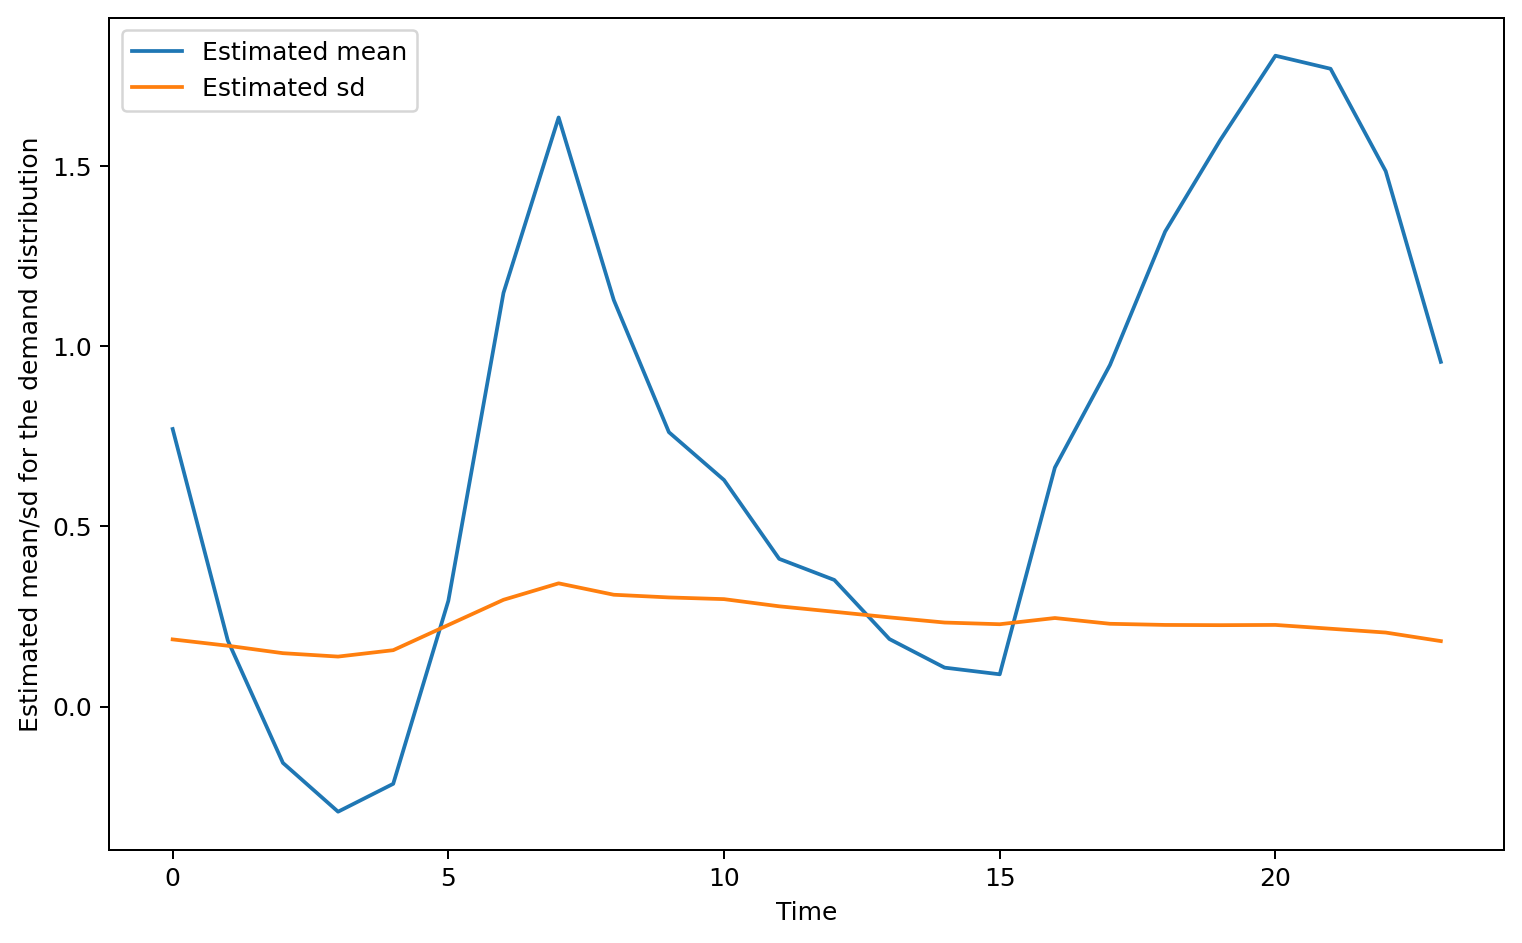

In [59]:
plt.figure(figsize=(10, 6), dpi=180)
plt.plot(opt_mean.values(), label='Estimated mean')
plt.plot(opt_sd.values(), label='Estimated sd')
plt.ylabel('Estimated mean/sd for the demand distribution')
plt.xlabel('Time')
plt.legend()
plt.show()

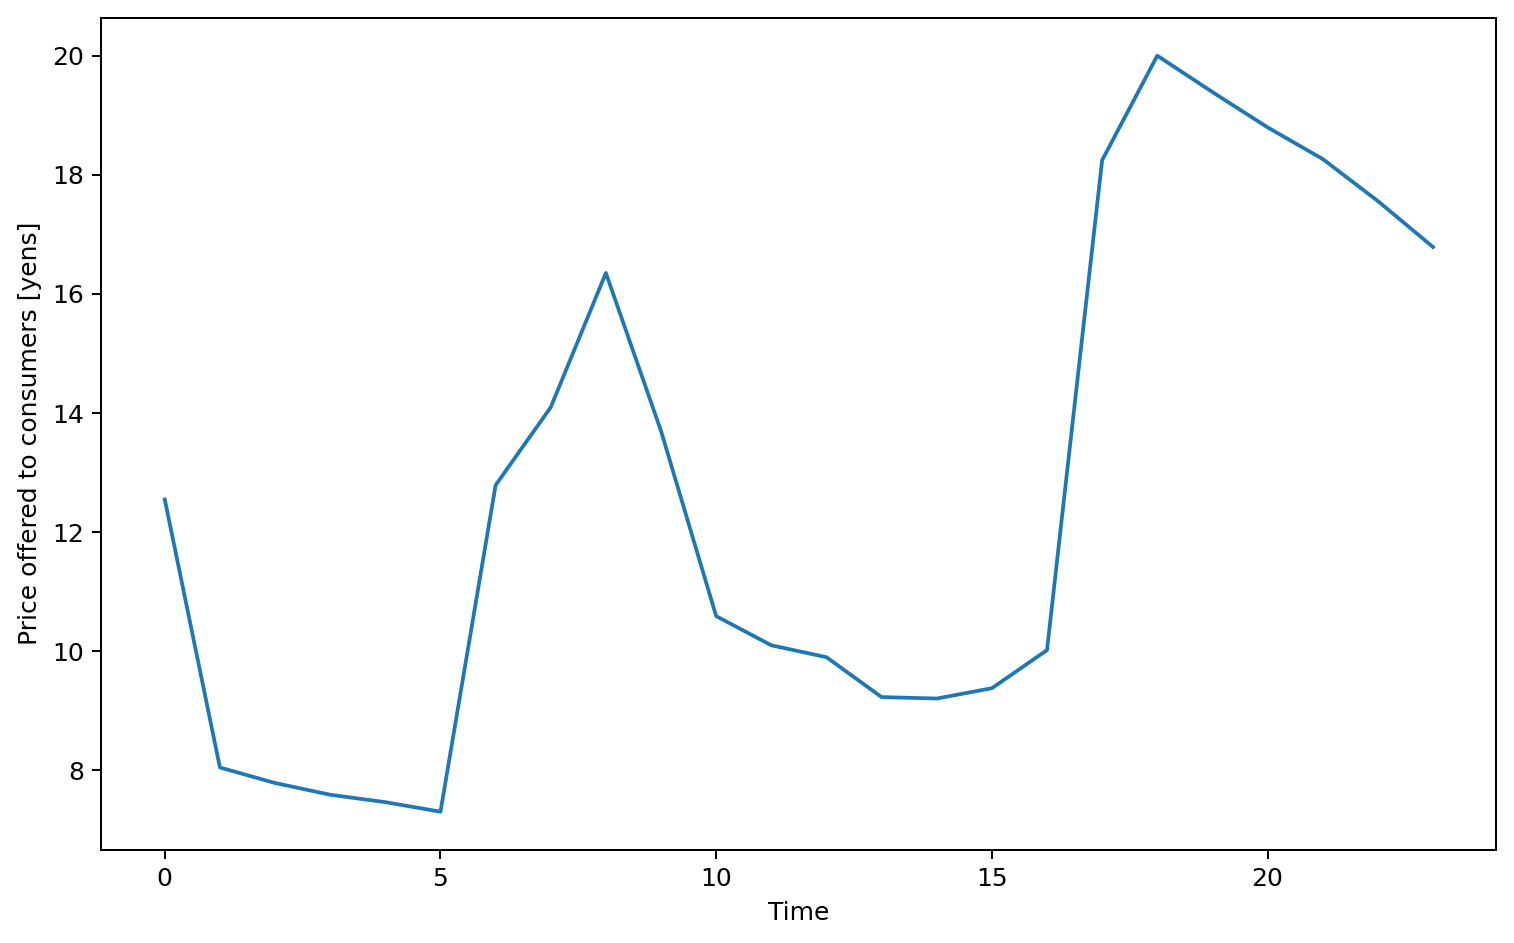

In [60]:
plt.figure(figsize=(10, 6), dpi=180)
plt.plot(opt_price.values())
plt.ylabel('Price offered to consumers [yens]')
plt.xlabel('Time')
plt.show()